# Results_paper

Figures and regressions for the Afghanistan market-activity paper.

The notebook is self-contained: it reads only from `processed_data/` (written
by `NTL_processing/06_export_processed_ntl.py` and `build_event_study_panel.py`)
plus the monthly VIIRS rasters, which are needed for one thing only — the
Kabul reference value in Section 3.

**Outputs**

| Section | Output | Goes to |
|---|---|---|
| 4 | CDF of nighttime light emissions, 2018 and 2025 | `output_paper/figures/` |
| 6 | Event-study workbook and coefficient figure | `output_paper/event_study/` |

**Nighttime lights convention.** All NTL here is BNR-filtered (background
noise reduction) using *each year's own* `average_masked` composite as that
year's reference mask, never a single static reference year. Light is measured
as mean radiance per valid pixel in a 10 km geodesic buffer around each market.

In [1]:
import os
import sys
import glob
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats as _st

# Locate code_paper/NTL_processing/config.py whether the kernel was started in
# code_paper itself or one level above it.
_candidates = [os.getcwd(), os.path.join(os.getcwd(), "code_paper"),
               os.path.dirname(os.getcwd())]
NB_DIR = next((p for p in _candidates
               if os.path.exists(os.path.join(p, "NTL_processing", "config.py"))), None)
if NB_DIR is None:
    raise RuntimeError("Could not find NTL_processing/config.py. Start the kernel in "
                       "the code_paper folder, or set MAI_BASE.")
sys.path.insert(0, os.path.join(NB_DIR, "NTL_processing"))
from config import (BASE, DATA, PROCESSED, OUTPUT, VIIRS_DIR, MASK_DIR,
                    KABUL_LON, KABUL_LAT, BUFFER_KM, MAX_RAD_CAP)

OUT_FIG = os.path.join(OUTPUT, "figures")
OUT_ES = os.path.join(OUTPUT, "event_study")
os.makedirs(OUT_FIG, exist_ok=True)
os.makedirs(OUT_ES, exist_ok=True)

YEARS = list(range(2018, 2026))
FIG_YEARS = [2018, 2025]

# Okabe-Ito, colourblind-safe.
BLUE, ORANGE = "#0072B2", "#E69F00"

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200,
                     "font.size": 11, "axes.titlesize": 12})

print("base      :", BASE)
print("processed :", PROCESSED)
print("outputs   :", OUTPUT)

base      : C:\Users\obarriga\Box\WorldBank\Geospatial\MarketActivityIndex
processed : C:\Users\obarriga\Box\WorldBank\Geospatial\MarketActivityIndex\processed_data
outputs   : C:\Users\obarriga\Box\WorldBank\Geospatial\MarketActivityIndex\output_paper


## 1. Load the processed data

In [2]:
ntl = pd.read_csv(os.path.join(PROCESSED, "ntl_bnr_866markets_4years.csv"), low_memory=False)
groups = pd.read_csv(os.path.join(PROCESSED, "market_groups.csv"), low_memory=False)
panel = pd.read_stata(os.path.join(PROCESSED, "event_study_panel.dta"))

ntl = ntl.merge(groups[["mkt_uid", "group"]], on="mkt_uid", how="left")
assert ntl.group.notna().all()

print("NTL buffer stats :", ntl.shape)
print("event-study panel:", panel.shape)
print()
print(ntl.group.value_counts().to_string())

NTL buffer stats : (866, 150)
event-study panel: (1084, 14)

group
OSM only       646
Periodic       137
OSM overlap     83


## 2. Market-year light measure

For each market and year, take the **median across the twelve monthly values**
of total BNR-filtered radiance summed over the 10 km buffer. Markets with no
valid pixel in a month are missing there; a market whose median is zero or
missing is treated as dark that year.

Because this is a sum rather than a per-pixel mean, it scales with buffer
area, so anything compared against it — including the Kabul reference in the
next section — must use the same 10 km buffer.

In [3]:
def median_monthly_light(df, year):
    """Median across the 12 monthly SUM_BNR values, per market, for `year`."""
    cols = sorted(c for c in df.columns if c.startswith("SUM_BNR_%d" % year))
    assert len(cols) == 12, "%d: expected 12 monthly columns, got %d" % (year, len(cols))
    return df[cols].median(axis=1, skipna=True).fillna(0.0).clip(lower=0.0)


for y in FIG_YEARS:
    ntl["light_%d" % y] = median_monthly_light(ntl, y)

lit_share = pd.DataFrame({
    "n": ntl.groupby("group").size(),
    **{"positive light %d" % y: ntl.groupby("group")["light_%d" % y].apply(lambda s: (s > 0).mean())
       for y in FIG_YEARS},
})
print((100 * lit_share[[c for c in lit_share.columns if c != "n"]]).round(1)
      .join(lit_share[["n"]]).to_string())

             positive light 2018  positive light 2025    n
group                                                     
OSM only                    47.7                 58.7  646
OSM overlap                 65.1                 84.3   83
Periodic                    56.9                 73.7  137


## 3. Nighttime light in downtown Kabul

The CDF figures carry a reference line for Kabul. It is computed here on
exactly the same basis as the market values: a 10 km geodesic buffer around
Kabul city centre, BNR-filtered with that year's own reference mask, taking
the median across the twelve monthly buffer totals. The buffer is the same
10 km used for the markets, which is what makes a summed measure comparable.
The per-pixel mean is computed and cached alongside it for reference.

This is the one step that reads the monthly VIIRS rasters. The result is
cached to `processed_data/kabul_reference_10km_bnr.csv`, so later runs skip it.

In [4]:
from pyproj import Geod
import rasterio
from rasterstats import zonal_stats
from shapely.geometry import Polygon

GEOD = Geod(ellps="WGS84")
KABUL_CACHE = os.path.join(PROCESSED, "kabul_reference_10km_bnr.csv")


def geodesic_circle(lon, lat, radius_km=BUFFER_KM, n_points=72):
    """True geodesic circle in EPSG:4326 - same construction as the market buffers."""
    angles = np.linspace(0, 360, n_points, endpoint=False)
    lons, lats, _ = GEOD.fwd(np.full(n_points, lon), np.full(n_points, lat),
                             angles, np.full(n_points, radius_km * 1000.0))
    return Polygon(zip(lons, lats))


def kabul_monthly_stats(year):
    """Monthly BNR radiance in a 10 km buffer on Kabul city centre.

    Returns a frame indexed by YYYYMM with the buffer total ('sum') and the
    per-valid-pixel average ('mean').
    """
    geom = [geodesic_circle(KABUL_LON, KABUL_LAT)]
    with rasterio.open(os.path.join(MASK_DIR, "afg_viirs_annual_masked_%d.tif" % year)) as ds:
        mask_bool = ds.read(1) > 0

    out = {}
    tifs = sorted(f for f in glob.glob(os.path.join(VIIRS_DIR, "afg_viirs_%d*.tif" % year))
                  if "cf_cvg" not in os.path.basename(f))
    for tif in tifs:
        m = re.search(r"afg_viirs_(\d{6})\.tif$", os.path.basename(tif))
        if not m:
            continue
        with rasterio.open(tif) as ds:
            avg_rad, transform = ds.read(1), ds.transform
        if avg_rad.shape != mask_bool.shape:
            out[m.group(1)] = {"sum": np.nan, "mean": np.nan}
            continue
        valid = mask_bool & (avg_rad > 0) & (avg_rad < MAX_RAD_CAP) & ~np.isnan(avg_rad)
        bnr = np.where(valid, avg_rad, np.nan).astype("float64")
        s = zonal_stats(geom, bnr, affine=transform, stats=["sum", "mean"],
                        nodata=np.nan, all_touched=False)[0]
        out[m.group(1)] = {"sum": s["sum"], "mean": s["mean"]}
    return pd.DataFrame(out).T.astype("float64")


NEEDED = ["kabul_median_sum", "kabul_median_mean_radiance", "n_months"]

kabul = None
if os.path.exists(KABUL_CACHE):
    cached = pd.read_csv(KABUL_CACHE).set_index("year")
    if all(c in cached.columns for c in NEEDED) and set(FIG_YEARS) <= set(cached.index):
        kabul = cached
        print("loaded cached Kabul reference values")
    else:
        print("cache is stale (missing columns or years) - recomputing")

if kabul is None:
    rows = []
    for y in FIG_YEARS:
        monthly = kabul_monthly_stats(y)
        rows.append({"year": y,
                     "kabul_median_sum": float(monthly["sum"].median(skipna=True)),
                     "kabul_median_mean_radiance": float(monthly["mean"].median(skipna=True)),
                     "n_months": int(monthly["sum"].notna().sum())})
        print("%d: %d months, median buffer sum = %.1f (per-pixel mean = %.2f)"
              % (y, rows[-1]["n_months"], rows[-1]["kabul_median_sum"],
                 rows[-1]["kabul_median_mean_radiance"]))
    kabul = pd.DataFrame(rows).set_index("year")
    kabul.to_csv(KABUL_CACHE)
    print("cached to", KABUL_CACHE)

# The figures plot the buffer total, so the reference line uses the same.
KABUL_REF = kabul["kabul_median_sum"].to_dict()
print()
print("Kabul reference (buffer total, 10 km):",
      {y: round(v, 1) for y, v in KABUL_REF.items()})

loaded cached Kabul reference values

Kabul reference (buffer total, 10 km): {2018: 18464.0, 2025: 17353.2}


## 4. Cumulative distribution of nighttime light emissions

Periodic markets against OSM-only markets, for 2018 and 2025.

The curve **starts at the share of markets with any light** and accumulates
from there across the lit markets' brightness, reaching 100% at the brightest
market. Dark markets carry no brightness information, so they set the starting
height and are not placed anywhere on the horizontal axis. A vertical riser
carries each curve down to the x-axis at its leftmost value, so the lines
never run into the y-axis.

The axis begins at zero on the log scale, i.e. a buffer total of 1. The few
lit markets dimmer than that are clipped to the left edge, which lifts the
visible starting height marginally above the positive-light share; both
numbers are printed below.

2018  Periodic markets (n=137)     lit share 56.9%, curve at x=0 is 58.6%
2018  OSM-only markets (n=646)     lit share 47.7%, curve at x=0 is 48.9%


  saved cdf_nighttime_light_2018_periodic_vs_osm.png
2025  Periodic markets (n=137)     lit share 73.7%, curve at x=0 is 74.8%
2025  OSM-only markets (n=646)     lit share 58.7%, curve at x=0 is 59.0%


  saved cdf_nighttime_light_2025_periodic_vs_osm.png


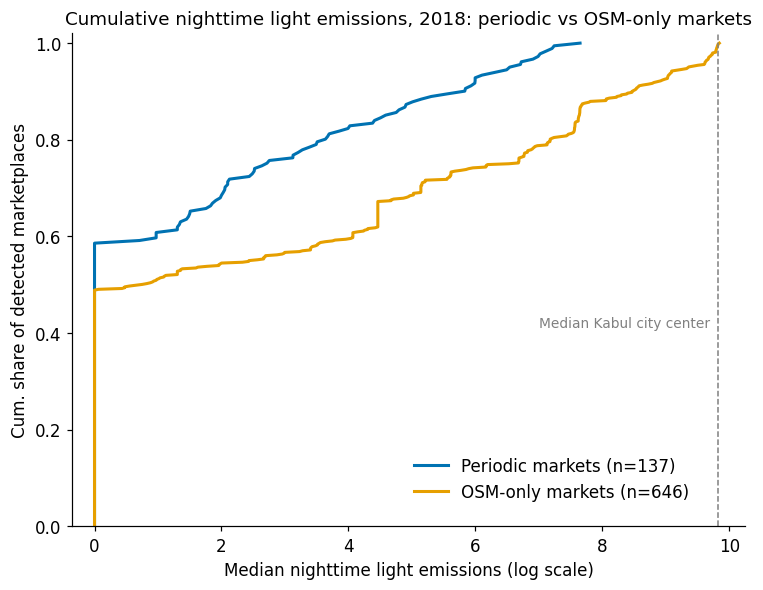

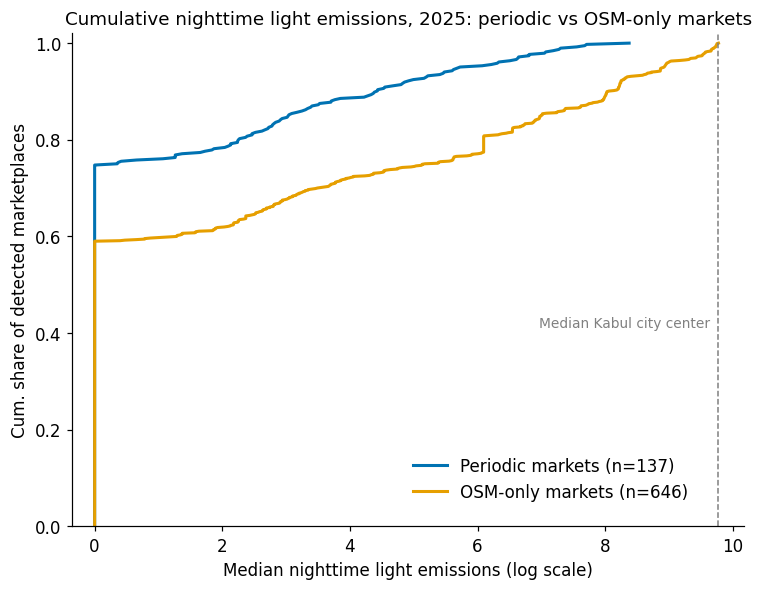

In [5]:
FLOOR = 1.0  # lit markets below this pile up at the plot's left edge, log = 0


def forced_start_cdf(values, floor=FLOOR):
    """(x, y) for a CDF that starts at the lit share and rises to 1.

    y(x) = lit_share + (1 - lit_share) * F_lit(x), where F_lit is the ECDF of
    log light among markets with positive light. Lit markets dimmer than
    `floor` are clipped to it so that the axis can start at log(floor) = 0.
    """
    v = np.asarray(values, dtype="float64")
    lit_share = float((v > 0).mean())
    lit = np.sort(np.clip(v[v > 0], floor, None))
    x = np.log(lit)
    y = lit_share + (1.0 - lit_share) * (np.arange(1, len(lit) + 1) / len(lit))
    return x, y, lit_share


def draw_cdf(year, out_path):
    col = "light_%d" % year
    series = [("Periodic markets (n=%d)" % (ntl.group == "Periodic").sum(),
               ntl.loc[ntl.group == "Periodic", col], BLUE),
              ("OSM-only markets (n=%d)" % (ntl.group == "OSM only").sum(),
               ntl.loc[ntl.group == "OSM only", col], ORANGE)]

    curves = [(lab, forced_start_cdf(s), c) for lab, s, c in series]
    kabul_x = np.log(KABUL_REF[year])
    x_left = -0.35
    x_right = max(max(cx.max() for _, (cx, _, _), _ in curves), kabul_x) + 0.4

    fig, ax = plt.subplots(figsize=(7, 5.5))
    for lab, (x, y, lit_share), color in curves:
        # A vertical riser at the leftmost value carries the curve down to the
        # x-axis, so the line never runs into the y-axis.
        ax.plot(np.concatenate([[x[0]], x]), np.concatenate([[0.0], y]),
                color=color, linewidth=2, label=lab)
        print("%d  %-28s lit share %.1f%%, curve at x=0 is %.1f%%"
              % (year, lab, 100 * lit_share, 100 * y[x <= 0].max() if (x <= 0).any()
                 else 100 * lit_share))

    ax.axvline(kabul_x, color="gray", linestyle="--", linewidth=1)
    ax.text(kabul_x - 0.12, 0.42, "Median Kabul city center",
            color="gray", fontsize=9, va="center", ha="right")

    ax.set_xlim(x_left, x_right)
    ax.set_ylim(0, 1.02)
    ax.set_xlabel("Median nighttime light emissions (log scale)")
    ax.set_ylabel("Cum. share of detected marketplaces")
    ax.set_title("Cumulative nighttime light emissions, %d: periodic vs OSM-only markets" % year)
    ax.legend(loc="lower right", bbox_to_anchor=(0.94, 0.02), frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    fig.savefig(out_path, bbox_inches="tight")
    print("  saved", os.path.basename(out_path))
    return fig


for y in FIG_YEARS:
    draw_cdf(y, os.path.join(OUT_FIG, "cdf_nighttime_light_%d_periodic_vs_osm.png" % y))
plt.show()

## 5. Event study

Year dummies (2020 omitted) interacted with three time-invariant baseline
market characteristics: once-a-week trading, distance to the nearest OSM
market, and log catchment population. Market and year fixed effects; standard
errors clustered by district. Time-varying controls: log district deaths per
100,000 and growing-season NDVI deviation.

| Model | Sample | Outcome |
|---|---|---|
| A | all 137 markets | market activity index, 2020 = 100 |
| A | always-lit markets | market activity index, 2020 = 100 |
| B | ever-lit markets | log Feb-Jun median BNR radiance |

In [6]:
NONBASE_YEARS = [y for y in YEARS if y != 2020]
CHARS = {"once_a_week_c": "once_a_week", "dist_osm_c": "dist_osm", "log_pop_c": "log_pop"}
PRE, POST = [2018, 2019], [2021, 2022, 2023, 2024, 2025]
REQ = ["once_a_week_c", "dist_osm_c", "log_pop_c", "log_deaths_pc", "ndvi_dev"]
YRS_ORDER = YEARS


def _clus(formula, data, group):
    """OLS with cluster-robust SEs and p-values from t(G-1)."""
    g = data[group]
    f = smf.ols(formula, data=data).fit(cov_type="cluster", cov_kwds={"groups": g}, use_t=True)
    G = g.nunique()
    f._p = {k: 2 * (1 - _st.t.cdf(abs(f.params[k] / f.bse[k]), G - 1)) for k in f.params.index}
    return f


def add_centered(df, market_cols=("once_a_week", "dist_osm", "log_pop")):
    d = df.copy()
    means = d.drop_duplicates("mktID")[list(market_cols)].mean()
    for c in market_cols:
        d[c + "_c"] = d[c] - means[c]
    for cvar in CHARS:
        for y in NONBASE_YEARS:
            d["%s_%d" % (cvar, y)] = d[cvar] * (d.year == y)
    return d, means


def _formula(outcome):
    inter = " + ".join("%s_%d" % (cvar, y) for cvar in CHARS for y in NONBASE_YEARS)
    return ("%s ~ C(mktID) + C(year, Treatment(2020)) + %s + log_deaths_pc + ndvi_dev"
            % (outcome, inter))


def run_model(df, outcome, label, dropcols):
    d, _ = add_centered(df)
    d = d.dropna(subset=dropcols)
    f = _clus(_formula(outcome), d, "Pcode_24")
    print("=== %s ===  n=%d  markets=%d  clusters=%d  R2=%.4f"
          % (label, int(f.nobs), d.mktID.nunique(), d.Pcode_24.nunique(), f.rsquared))
    return f, d


def joint_test(f, cvar, years):
    terms = ["%s_%d" % (cvar, y) for y in years if "%s_%d" % (cvar, y) in f.params.index]
    if not terms:
        return np.nan
    return float(f.wald_test(" , ".join("%s = 0" % t for t in terms), use_f=True).pvalue)

In [7]:
lit_markets = sorted(panel.loc[panel.lit_market == 1, "mktID"].unique())
ever_lit_markets = sorted(panel.loc[panel.ever_lit_market == 1, "mktID"].unique())
lit_panel = panel[panel.mktID.isin(lit_markets)].copy()
ever_panel = panel[panel.mktID.isin(ever_lit_markets)].copy()
print("always-lit markets: %d    ever-lit markets: %d\n" % (len(lit_markets), len(ever_lit_markets)))

fA_all, dA_all = run_model(panel, "y_activity",
                           "Model A - all markets", REQ + ["y_activity"])
fA_lit, dA_lit = run_model(lit_panel, "y_activity",
                           "Model A - always-lit markets (n=%d)" % len(lit_markets),
                           REQ + ["y_activity"])
fB_ever, dB_ever = run_model(ever_panel, "log_feb_jun_bnr",
                             "Model B - ever-lit markets (n=%d)" % len(ever_lit_markets),
                             REQ + ["log_feb_jun_bnr"])

always-lit markets: 52    ever-lit markets: 107

=== Model A - all markets ===  n=1077  markets=136  clusters=71  R2=0.4826


=== Model A - always-lit markets (n=52) ===  n=416  markets=52  clusters=35  R2=0.5579
=== Model B - ever-lit markets (n=107) ===  n=600  markets=106  clusters=63  R2=0.8992


### Event-study coefficient figure

saved C:\Users\obarriga\Box\WorldBank\Geospatial\MarketActivityIndex\output_paper\event_study\event_study_everlit_figure.png


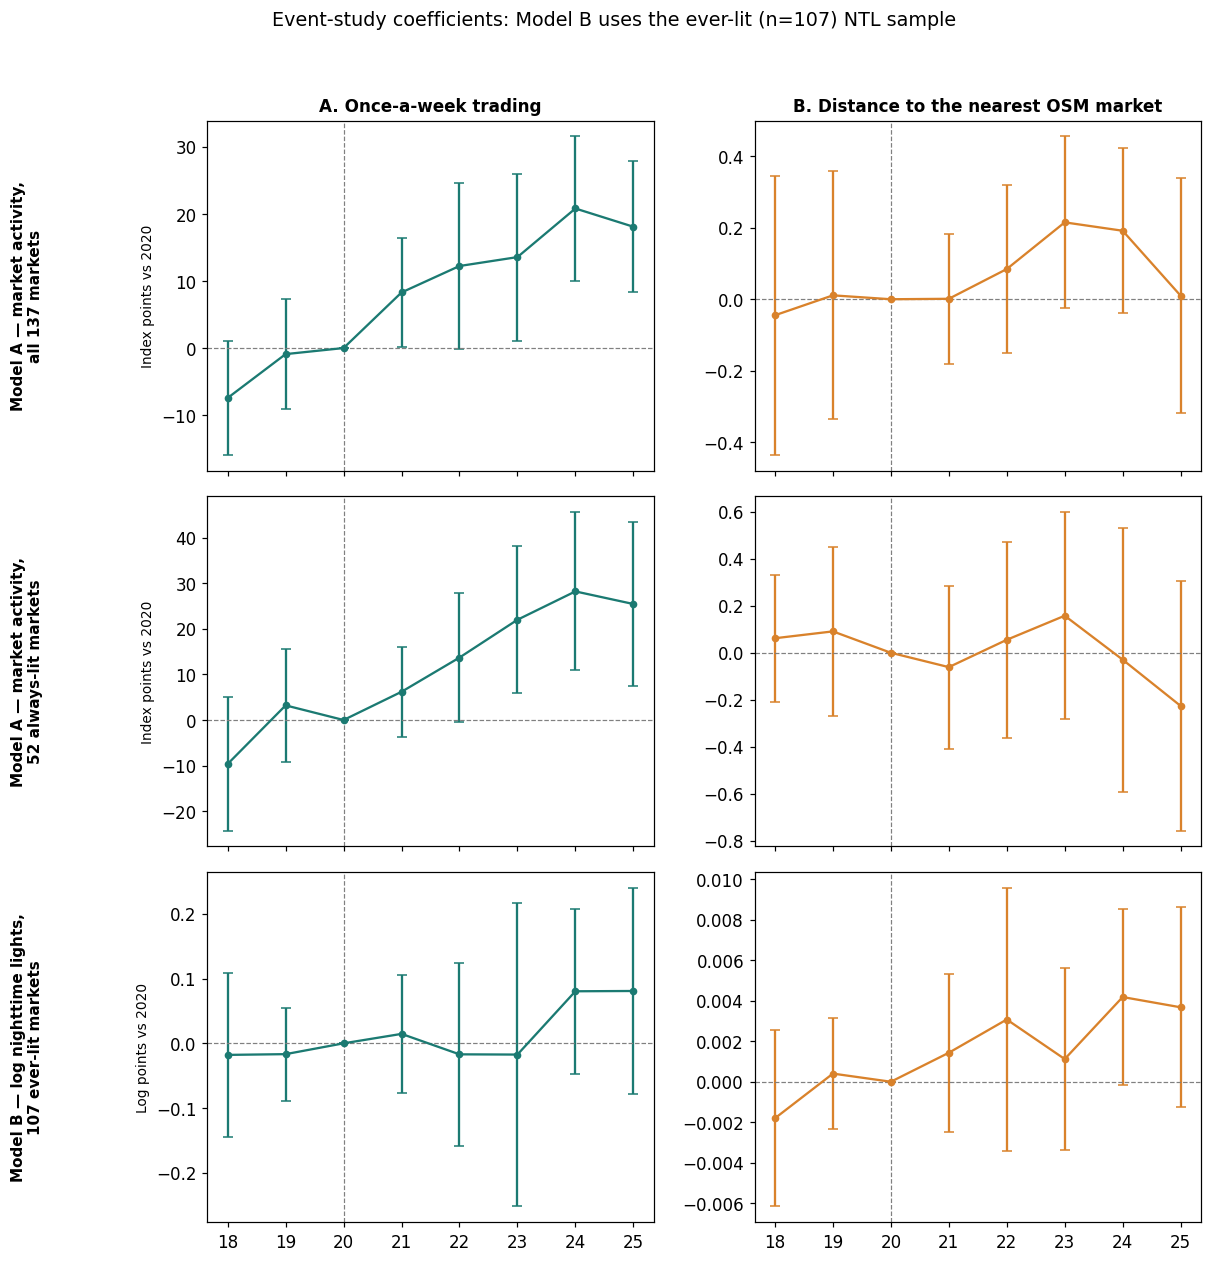

In [8]:
def new_series(f, cvar):
    return {y: (f.params["%s_%d" % (cvar, y)], f.bse["%s_%d" % (cvar, y)])
            for y in NONBASE_YEARS}


def to_xy(series):
    x, y, lo, hi = [], [], [], []
    for yr in YEARS:
        if yr == 2020:
            x.append(yr); y.append(0.0); lo.append(0.0); hi.append(0.0)
        else:
            c, se = series[yr]
            x.append(yr); y.append(c); lo.append(c - 1.96 * se); hi.append(c + 1.96 * se)
    return x, y, lo, hi


rows = [
    ("Model A — market activity,\nall %d markets" % panel.mktID.nunique(),
     fA_all, "Index points vs 2020"),
    ("Model A — market activity,\n%d always-lit markets" % len(lit_markets),
     fA_lit, "Index points vs 2020"),
    ("Model B — log nighttime lights,\n%d ever-lit markets" % len(ever_lit_markets),
     fB_ever, "Log points vs 2020"),
]
cols = [("A. Once-a-week trading", "once_a_week_c", "#1b7a72"),
        ("B. Distance to the nearest OSM market", "dist_osm_c", "#d9822b")]

fig, axes = plt.subplots(3, 2, figsize=(11, 11.5), sharex=True)
for i, (rtitle, f, ylab) in enumerate(rows):
    for j, (ctitle, cvar, color) in enumerate(cols):
        ax = axes[i, j]
        x, yv, lo, hi = to_xy(new_series(f, cvar))
        x = np.array(x, dtype=float); yv = np.array(yv, dtype=float)
        lo = np.array(lo, dtype=float); hi = np.array(hi, dtype=float)
        ax.errorbar(x, yv, yerr=np.vstack([yv - lo, hi - yv]), fmt="o-", color=color,
                    ecolor=color, capsize=3, linewidth=1.5, markersize=4)
        ax.axhline(0, ls="--", color="gray", linewidth=0.8)
        ax.axvline(2020, ls="--", color="gray", linewidth=0.8)
        ax.set_xticks(YEARS)
        ax.set_xticklabels([str(y)[2:] for y in YEARS])
        if i == 0:
            ax.set_title(ctitle, fontsize=11, fontweight="bold")
        if j == 0:
            ax.set_ylabel(ylab, fontsize=9)

fig.suptitle("Event-study coefficients: Model B uses the ever-lit (n=%d) NTL sample"
             % len(ever_lit_markets), fontsize=12.5, y=0.995)
fig.tight_layout(rect=[0.09, 0, 1, 0.97])
for i, (rtitle, f, ylab) in enumerate(rows):
    pos = axes[i, 0].get_position()
    fig.text(0.015, (pos.y0 + pos.y1) / 2, rtitle, rotation=90, va="center",
             ha="center", fontsize=10, fontweight="bold")

es_fig_path = os.path.join(OUT_ES, "event_study_everlit_figure.png")
fig.savefig(es_fig_path, bbox_inches="tight")
print("saved", es_fig_path)
plt.show()

## 6. Export the regression results

One sheet per model, laid out as in the published workbook: per-year
coefficients for each baseline characteristic, the time-varying controls, the
specification block, and joint tests of the pre-2020 and post-2020 interaction
terms.

In [9]:
COEF_LABELS = {"once_a_week_c": "Once-a-week trading",
               "dist_osm_c": "Distance to OSM market (centred)",
               "log_pop_c": "Log catchment population (centred)"}


def build_sheet(f, d, label, outcome_note):
    rows = [[label],
            ["Event study, 2018-2025. Year dummies (2020 omitted) interacted "
             "with three baseline market characteristics."],
            [outcome_note], [],
            ["Variable", "Coefficient", "Std. error", "t", "p-value",
             "95% CI low", "95% CI high"]]
    for cvar, lab in COEF_LABELS.items():
        rows.append([lab, "", "", "", "", "", ""])
        for y in YRS_ORDER:
            if y == 2020:
                rows.append(["   %d" % y, "omitted (base year)", "", "", "", "", ""])
                continue
            t = "%s_%d" % (cvar, y)
            c, s, p = f.params[t], f.bse[t], f._p[t]
            ci = f.conf_int().loc[t]
            rows.append(["   %d" % y, c, s, c / s, p, ci[0], ci[1]])
        rows.append([])

    rows.append(["Time-varying controls", "", "", "", "", "", ""])
    for k, lab in [("log_deaths_pc", "Log(1+district deaths per 100,000)"),
                   ("ndvi_dev", "Growing-season NDVI deviation (SD)")]:
        c, s, p = f.params[k], f.bse[k], f._p[k]
        ci = f.conf_int().loc[k]
        rows.append([lab, c, s, c / s, p, ci[0], ci[1]])

    rows.append([])
    rows.append(["Specification", "", "", "", "", "", ""])
    rows.append(["Market fixed effects", "Yes", "", "", "", "", ""])
    rows.append(["Year fixed effects", "Yes", "", "", "", "", ""])
    rows.append(["Standard errors", "Clustered by district", "", "", "", "", ""])
    rows.append(["Clusters (districts)", d.Pcode_24.nunique(), "", "", "", "", ""])
    rows.append(["Markets", d.mktID.nunique(), "", "", "", "", ""])
    rows.append(["Observations", int(f.nobs), "", "", "", "", ""])
    rows.append(["R-squared", round(f.rsquared, 4), "", "", "", "", ""])
    for cvar, lab in COEF_LABELS.items():
        rows.append(["Joint test, %s: pre-2020 p-value" % lab.lower(),
                     round(joint_test(f, cvar, PRE), 4), "", "", "", "", ""])
        rows.append(["Joint test, %s: post-2020 p-value" % lab.lower(),
                     round(joint_test(f, cvar, POST), 4), "", "", "", "", ""])
    return pd.DataFrame(rows)


sheets = [
    ("Model A - all markets",
     build_sheet(fA_all, dA_all, "Model A - all markets",
                 "Outcome: Market activity index, each market rescaled to its own 2020 = 100")),
    ("Model A - lit markets",
     build_sheet(fA_lit, dA_lit, "Model A - lit markets (always-lit, new BNR)",
                 "Outcome: Market activity index, 2020=100; restricted to the %d markets "
                 "with positive per-year-corrected BNR radiance in every year 2018-2025"
                 % len(lit_markets))),
    ("Model B - ever-lit NTL",
     build_sheet(fB_ever, dB_ever, "Model B - filtered NTL (ever-lit, new BNR)",
                 "Outcome: Log of the February-June median of monthly background-removed "
                 "radiance in the 10 km buffer (per-year-corrected reference mask); restricted "
                 "to the %d markets with positive annual mean BNR radiance in at least one year "
                 "2018-2025 (unbalanced panel: market-years the market was dark drop as missing "
                 "outcome)" % len(ever_lit_markets))),
]

xlsx_path = os.path.join(OUT_ES, "AFG_event_study_models_EVERLIT.xlsx")
with pd.ExcelWriter(xlsx_path, engine="openpyxl") as xl:
    for name, sheet in sheets:
        sheet.to_excel(xl, sheet_name=name, index=False, header=False)
print("saved", xlsx_path)

C:\Users\obarriga\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.8_qbz5n2kfra8p0\LocalCache\local-packages\Python38\site-packages\statsmodels\base\model.py:1914: FutureWarning: The behavior of wald_test will change after 0.14 to returning scalar test statistic values. To get the future behavior now, set scalar to True. To silence this message while retaining the legacy behavior, set scalar to False.
  warnings.warn(


saved C:\Users\obarriga\Box\WorldBank\Geospatial\MarketActivityIndex\output_paper\event_study\AFG_event_study_models_EVERLIT.xlsx


### What was written

In [10]:
for folder in [OUT_FIG, OUT_ES]:
    print(os.path.relpath(folder, BASE))
    for fn in sorted(os.listdir(folder)):
        print("   ", fn)

output_paper\figures
    cdf_nighttime_light_2018_periodic_vs_osm.png
    cdf_nighttime_light_2025_periodic_vs_osm.png
output_paper\event_study
    AFG_event_study_models_EVERLIT.xlsx
    event_study_everlit_figure.png
